In [1]:
!unzip -o /content/freshcart_dataset.zip -d /content/freshcart_project


Archive:  /content/freshcart_dataset.zip
  inflating: /content/freshcart_project/data/raw/sales.csv  
  inflating: /content/freshcart_project/data/raw/products.csv  
  inflating: /content/freshcart_project/data/raw/stores.csv  
  inflating: /content/freshcart_project/data/raw/promotions.csv  
  inflating: /content/freshcart_project/data/raw/calendar.csv  


In [2]:

import pandas as pd
import os

BASE = "/content/freshcart_project/data/raw"

sales = pd.read_csv(f"{BASE}/sales.csv")
products = pd.read_csv(f"{BASE}/products.csv")
stores = pd.read_csv(f"{BASE}/stores.csv")
promotions = pd.read_csv(f"{BASE}/promotions.csv")
calendar = pd.read_csv(f"{BASE}/calendar.csv")

print("SALES DATA")
display(sales.head())

print("PRODUCTS DATA")
display(products.head())

print("STORES DATA")
display(stores.head())

print("PROMOTIONS DATA")
display(promotions.head())

print("CALENDAR DATA")
display(calendar.head())

SALES DATA


,sale_id,date,store_id,product_id,units,revenue,promotion_code
0,TXN000001,2025-05-31,S11,P040,2,298.0,PR06
1,TXN000002,2025-07-05,S10,P013,8,1592.0,PR06
2,TXN000003,2025-01-24,S11,P015,3,597.0,PR06
3,TXN000004,2025-02-10,S04,P056,1,22.5,PR01
4,TXN000005,2025-05-23,S08,P041,6,210.0,PR06


PRODUCTS DATA


,product_id,product_name,category,brand,price_band,unit_price
0,P001,Dairy Item 01,Dairy,Milko,Budget,35.0
1,P002,Dairy Item 02,Dairy,FarmFresh,Premium,249.0
2,P003,Dairy Item 03,Dairy,FarmFresh,Mid-range,149.0
3,P004,Dairy Item 04,Dairy,Milko,Mid-range,99.0
4,P005,Dairy Item 05,Dairy,DailyDairy,Mid-range,99.0


STORES DATA


,store_id,store_name,city,format,floor_area_sqft
0,S01,FreshCart Chennai 1,Chennai,Express,12000
1,S02,FreshCart Coimbatore 1,Coimbatore,Standard,8500
2,S03,FreshCart Madurai 1,Madurai,Hypermarket,3200
3,S04,FreshCart Salem 1,Salem,Express,12000
4,S05,FreshCart Tiruchirappalli 1,Tiruchirappalli,Standard,3200


PROMOTIONS DATA


,promotion_code,campaign,discount_pct,duration_days
0,PR01,Weekend Saver,10,3
1,PR02,Festival Bonanza,20,7
2,PR03,Buy More Save More,15,14
3,PR04,New Customer Offer,5,10
4,PR05,Clearance Sale,25,5


CALENDAR DATA


,date,weekday,holiday,festival,season
0,2025-01-01,Wednesday,0.0,NaN,Winter
1,2025-01-02,Thursday,0.0,NaN,Winter
2,2025-01-03,Friday,0.0,NaN,Winter
3,2025-01-04,Saturday,0.0,NaN,Winter
4,2025-01-05,Sunday,0.0,NaN,Winter


In [3]:
print("Sales:", sales.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Promotions:", promotions.shape)
print("Calendar:", calendar.shape)


Sales: (4235, 7)
Products: (60, 6)
Stores: (12, 5)
Promotions: (6, 4)
Calendar: (365, 5)


In [4]:
# 1. Check missing values in all five datasets

datasets = {
    "Sales": sales,
    "Products": products,
    "Stores": stores,
    "Promotions": promotions,
    "Calendar": calendar
}

for name, df in datasets.items():
    print(f"\n===== {name} DATASET =====")
    print("Shape:", df.shape)
    print("\nMissing values:")
    print(df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())
    print("\nData types:")
    print(df.dtypes)


===== Sales DATASET =====
Shape: (4235, 7)

Missing values:
sale_id            0
date               0
store_id           0
product_id         0
units              0
revenue            0
promotion_code    66
dtype: int64

Duplicate rows: 35

Data types:
sale_id            object
date               object
store_id           object
product_id         object
units               int64
revenue           float64
promotion_code     object
dtype: object

===== Products DATASET =====
Shape: (60, 6)

Missing values:
product_id      0
product_name    0
category        0
brand           0
price_band      0
unit_price      0
dtype: int64

Duplicate rows: 0

Data types:
product_id       object
product_name     object
category         object
brand            object
price_band       object
unit_price      float64
dtype: object

===== Stores DATASET =====
Shape: (12, 5)

Missing values:
store_id           0
store_name         0
city               0
format             0
floor_area_sqft    0
dtype: int64

In [5]:
print("Zero units:", (sales["units"] == 0).sum())
print("Negative units:", (sales["units"] < 0).sum())
print("Zero revenue:", (sales["revenue"] == 0).sum())
print("Negative revenue:", (sales["revenue"] < 0).sum())

print("\nInconsistent product categories:")
print(products["category"].value_counts(dropna=False))

print("\nMissing promotion codes:")
print(sales["promotion_code"].isnull().sum())

Zero units: 15
Negative units: 15
Zero revenue: 0
Negative revenue: 0

Inconsistent product categories:
category
Produce      10
Bakery       10
Household    10
Dairy         9
Beverages     9
Snacks        9
dairy         1
BEVERAGES     1
 snackS       1
Name: count, dtype: int64

Missing promotion codes:
66


In [6]:
# Create copies so the original data remains unchanged
sales_clean = sales.copy()
products_clean = products.copy()
stores_clean = stores.copy()
promotions_clean = promotions.copy()
calendar_clean = calendar.copy()

# 1. Remove duplicate sales records
sales_clean = sales_clean.drop_duplicates()

# 2. Remove invalid sales with zero or negative units
sales_clean = sales_clean[sales_clean["units"] > 0].copy()

# 3. Handle missing promotion codes
sales_clean["promotion_code"] = (
    sales_clean["promotion_code"].fillna("UNKNOWN")
)

# 4. Standardize category names
products_clean["category"] = (
    products_clean["category"]
    .astype("string")
    .str.strip()
    .str.title()
)

# 5. Fill missing calendar flags
calendar_clean["holiday"] = calendar_clean["holiday"].fillna(0)

calendar_clean["festival"] = (
    calendar_clean["festival"].fillna("None")
)

calendar_clean["season"] = (
    calendar_clean["season"].fillna("Unknown")
)

print("Cleaning completed successfully!")
print("Original sales rows:", len(sales))
print("Cleaned sales rows:", len(sales_clean))
print("Cleaned product categories:")
print(products_clean["category"].value_counts())

Cleaning completed successfully!
Original sales rows: 4235
Cleaned sales rows: 4170
Cleaned product categories:
category
Dairy        10
Beverages    10
Snacks       10
Bakery       10
Produce      10
Household    10
Name: count, dtype: Int64


In [7]:
print("Remaining duplicate sales rows:",
      sales_clean.duplicated().sum())

print("Remaining invalid units:",
      (sales_clean["units"] <= 0).sum())

print("Remaining missing promotion codes:",
      sales_clean["promotion_code"].isnull().sum())

display(sales_clean.head())

Remaining duplicate sales rows: 0
Remaining invalid units: 0
Remaining missing promotion codes: 0


,sale_id,date,store_id,product_id,units,revenue,promotion_code
0,TXN000001,2025-05-31,S11,P040,2,298.0,PR06
1,TXN000002,2025-07-05,S10,P013,8,1592.0,PR06
2,TXN000003,2025-01-24,S11,P015,3,597.0,PR06
3,TXN000004,2025-02-10,S04,P056,1,22.5,PR01
4,TXN000005,2025-05-23,S08,P041,6,210.0,PR06


In [8]:
# Convert date columns into datetime format
sales_clean["date"] = pd.to_datetime(sales_clean["date"])
calendar_clean["date"] = pd.to_datetime(calendar_clean["date"])

# Merge sales with product details
df = pd.merge(
    sales_clean,
    products_clean,
    on="product_id",
    how="left"
)

# Merge with store details
df = pd.merge(
    df,
    stores_clean,
    on="store_id",
    how="left"
)

# Merge with promotion details
df = pd.merge(
    df,
    promotions_clean,
    on="promotion_code",
    how="left"
)

# Merge with calendar details
df = pd.merge(
    df,
    calendar_clean,
    on="date",
    how="left",
    suffixes=("", "_calendar")
)

print("All datasets merged successfully!")
print("Combined dataset shape:", df.shape)

display(df.head())

All datasets merged successfully!
Combined dataset shape: (4170, 23)


,sale_id,date,store_id,product_id,units,revenue,promotion_code,product_name,category,brand,...,city,format,floor_area_sqft,campaign,discount_pct,duration_days,weekday,holiday,festival,season
0,TXN000001,2025-05-31,S11,P040,2,298.0,PR06,Bakery Item 10,Bakery,BakeHouse,...,Madurai,Standard,8500,No Promotion,0.0,0.0,Saturday,0.0,None,Summer
1,TXN000002,2025-07-05,S10,P013,8,1592.0,PR06,Beverages Item 03,Beverages,BrewDay,...,Coimbatore,Express,4500,No Promotion,0.0,0.0,Saturday,0.0,None,Monsoon
2,TXN000003,2025-01-24,S11,P015,3,597.0,PR06,Beverages Item 05,Beverages,BrewDay,...,Madurai,Standard,8500,No Promotion,0.0,0.0,Friday,0.0,None,Winter
3,TXN000004,2025-02-10,S04,P056,1,22.5,PR01,Household Item 06,Household,Sparkle,...,Salem,Express,12000,Weekend Saver,10.0,3.0,Monday,0.0,None,Winter
4,TXN000005,2025-05-23,S08,P041,6,210.0,PR06,Produce Item 01,Produce,NaturePick,...,Vellore,Standard,3200,No Promotion,0.0,0.0,Friday,0.0,None,Summer


In [9]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values after merging:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Number of rows: 4170
Number of columns: 23

Column names:
['sale_id', 'date', 'store_id', 'product_id', 'units', 'revenue', 'promotion_code', 'product_name', 'category', 'brand', 'price_band', 'unit_price', 'store_name', 'city', 'format', 'floor_area_sqft', 'campaign', 'discount_pct', 'duration_days', 'weekday', 'holiday', 'festival', 'season']

Missing values after merging:
sale_id             0
date                0
store_id            0
product_id          0
units               0
revenue             0
promotion_code      0
product_name        0
category            0
brand               0
price_band          0
unit_price          0
store_name          0
city                0
format              0
floor_area_sqft     0
campaign           65
discount_pct       65
duration_days      65
weekday             0
holiday             0
festival            0
season              0
dtype: int64

Statistical summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
sale_id,4170,4170,TXN004200,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,4170,NaN,NaN,NaN,2025-07-05 10:41:57.410071808,2025-01-01 00:00:00,2025-04-06 00:00:00,2025-07-06 00:00:00,2025-10-04 00:00:00,2025-12-31 00:00:00,NaN
store_id,4170,12,S08,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,4170,60,P006,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN
units,4170.0,NaN,NaN,NaN,4.417026,1.0,3.0,4.0,6.0,21.0,2.409593
revenue,4170.0,NaN,NaN,NaN,641.386367,20.0,199.0,447.0,897.0,5187.0,594.765789
promotion_code,4170,7,PR06,2533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name,4170,60,Dairy Item 06,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,4170,6,Dairy,741,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,4170,16,NutriGo,464,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Extract time-based features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["day_of_week"] = df["date"].dt.dayofweek
df["quarter"] = df["date"].dt.quarter

# Weekend indicator: 1 = weekend, 0 = weekday
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

# Promotion indicator
df["is_promotion"] = (df["discount_pct"].fillna(0) > 0).astype(int)

# Revenue per unit
df["revenue_per_unit"] = (
    df["revenue"] / df["units"]
).round(2)

# Revenue relative to store floor area
df["revenue_per_sqft"] = (
    df["revenue"] / df["floor_area_sqft"]
).round(4)

print("Feature engineering completed!")
display(
    df[[
        "date", "month_name", "quarter", "is_weekend",
        "is_promotion", "revenue_per_unit", "revenue_per_sqft"
    ]].head(10)
)

Feature engineering completed!


,date,month_name,quarter,is_weekend,is_promotion,revenue_per_unit,revenue_per_sqft
0,2025-05-31,May,2,1,0,149.00,0.0351
1,2025-07-05,July,3,1,0,199.00,0.3538
2,2025-01-24,January,1,0,0,199.00,0.0702
3,2025-02-10,February,1,0,1,22.50,0.0019
4,2025-05-23,May,2,0,0,35.00,0.0656
5,2025-03-25,March,1,0,1,41.65,0.0651
6,2025-05-17,May,2,1,0,199.00,0.2388
7,2025-02-06,February,1,0,1,28.00,0.0249
8,2025-05-06,May,2,0,1,74.25,0.1392
9,2025-11-24,November,4,0,1,21.25,0.0170


In [11]:
import os

os.makedirs("/content/freshcart_project/data/cleaned", exist_ok=True)

df.to_csv(
    "/content/freshcart_project/data/cleaned/cleaned_sales_analysis.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


EDA dataset shape: (4170, 32)


,revenue
category,
Beverages,570567.55
Produce,546413.05
Snacks,466594.15
Dairy,392436.80
Bakery,379329.00
Household,319240.60


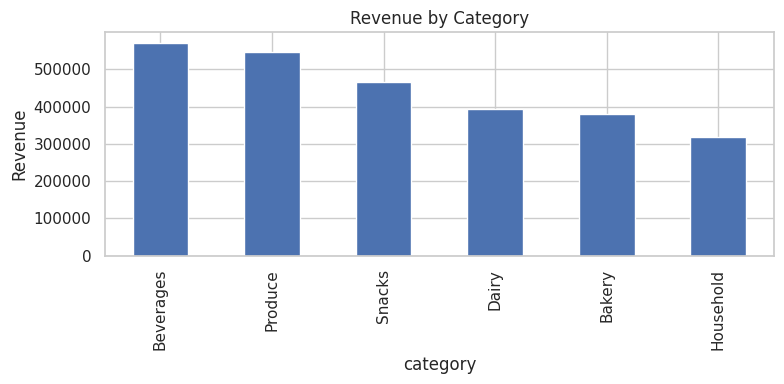

,revenue
store_id,
S02,236990.75
S03,232533.10
S08,232468.60
S09,231400.45
S07,225487.45
S12,224650.45
S05,222589.00
S11,220266.20
S04,215331.05


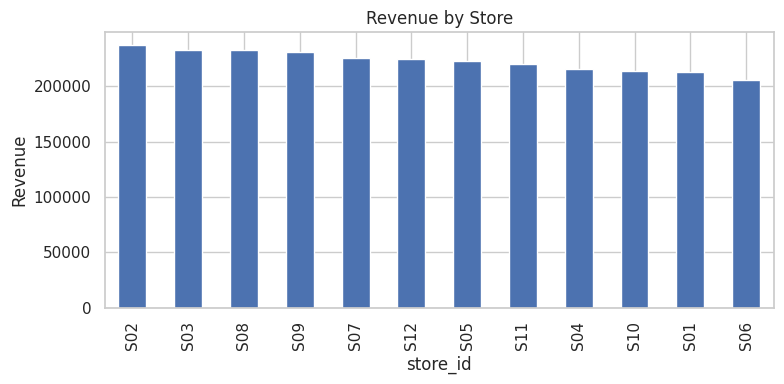

,total_revenue,total_units,average_units
campaign,,,
Buy More Save More,277989.95,2019,5.163683
Clearance Sale,113139.00,950,5.428571
Festival Bonanza,210652.00,1671,5.110092
New Customer Offer,120566.40,860,4.257426
No Promotion,1629845.00,10669,4.212002
Unknown / Missing,45781.90,301,4.630769
Weekend Saver,276606.90,1949,4.085954


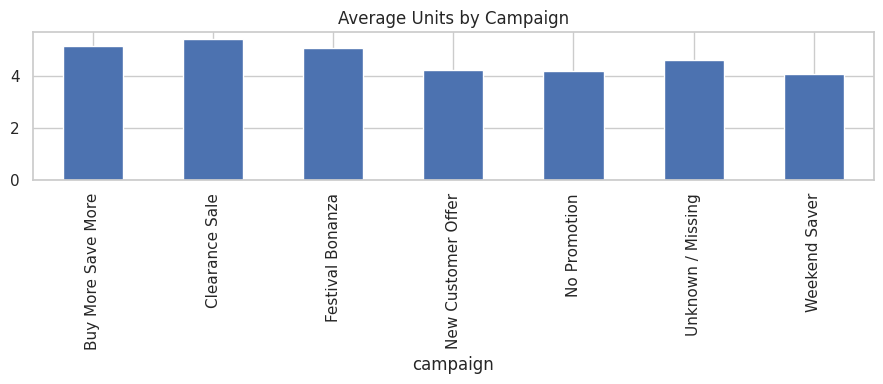

,total_revenue,average_units
festival,,
Christmas,4396.25,4.333333
Diwali,12734.70,4.904762
Independence Day,11226.05,5.705882
None,2613987.05,4.393703
Pongal,20928.90,6.650000
Tamil New Year,11308.20,6.555556


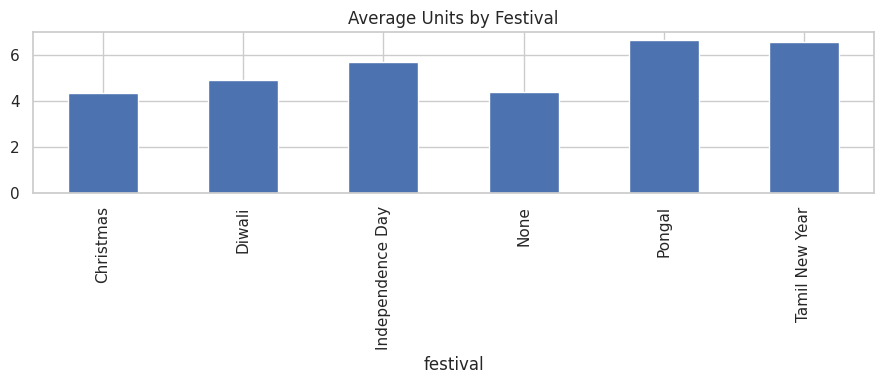

,season,product_name,total_units
107,Monsoon,Produce Item 08,148
70,Monsoon,Beverages Item 01,145
88,Monsoon,Dairy Item 09,135
118,Monsoon,Snacks Item 09,134
60,Monsoon,Bakery Item 01,133
232,Winter,Bakery Item 06,112
139,Summer,Beverages Item 10,109
170,Summer,Snacks Item 01,109
133,Summer,Beverages Item 04,108
173,Summer,Snacks Item 04,107


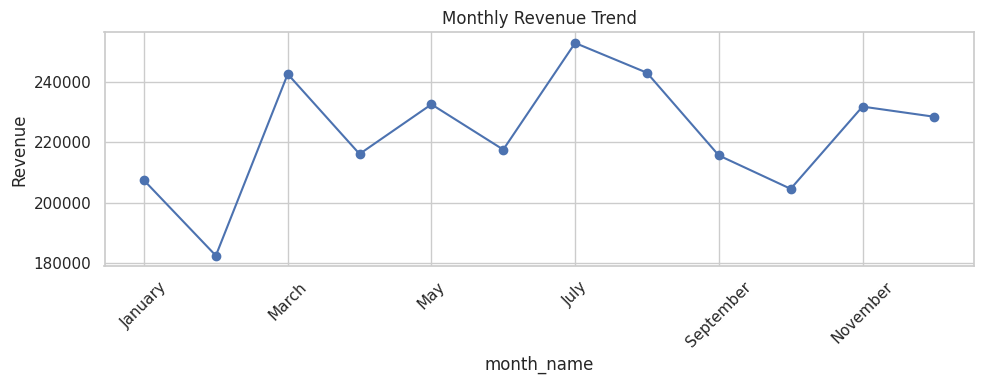

All six EDA analyses completed successfully!


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Prepare data for analysis
df["campaign"] = df["campaign"].fillna("Unknown / Missing")
df["festival"] = df["festival"].fillna("None")
df["season"] = df["season"].fillna("Unknown")
df["discount_pct"] = df["discount_pct"].fillna(0)

print("EDA dataset shape:", df.shape)

# 1. Revenue by category
category_revenue = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
display(category_revenue)

category_revenue.plot(kind="bar", title="Revenue by Category", figsize=(8, 4))
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# 2. Revenue by store
store_revenue = df.groupby("store_id")["revenue"].sum().sort_values(ascending=False)
display(store_revenue)

store_revenue.plot(kind="bar", title="Revenue by Store", figsize=(8, 4))
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# 3. Promotion analysis
promotion_summary = df.groupby("campaign").agg(
    total_revenue=("revenue", "sum"),
    total_units=("units", "sum"),
    average_units=("units", "mean")
)
display(promotion_summary)

promotion_summary["average_units"].plot(
    kind="bar", title="Average Units by Campaign", figsize=(9, 4)
)
plt.tight_layout()
plt.show()

# 4. Festival analysis
festival_summary = df.groupby("festival").agg(
    total_revenue=("revenue", "sum"),
    average_units=("units", "mean")
)
display(festival_summary)

festival_summary["average_units"].plot(
    kind="bar", title="Average Units by Festival", figsize=(9, 4)
)
plt.tight_layout()
plt.show()

# 5. Seasonal product analysis
seasonal_products = (
    df.groupby(["season", "product_name"])["units"]
    .sum()
    .reset_index(name="total_units")
)

display(
    seasonal_products.sort_values("total_units", ascending=False)
    .groupby("season")
    .head(5)
)

# 6. Monthly revenue trend
df["month_name"] = df["date"].dt.month_name()

monthly_sales = df.groupby("month_name")["revenue"].sum()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_sales = monthly_sales.reindex(month_order)

monthly_sales.plot(
    kind="line", marker="o",
    title="Monthly Revenue Trend", figsize=(10, 4)
)
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("All six EDA analyses completed successfully!")

In [15]:
# 1. Check data types and missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Encode categorical columns
categorical_cols = [
    "category",
    "brand",
    "format",
    "season",
    "festival"
]

encoded_df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", encoded_df.shape)

# 3. Feature selection using correlation
numeric_df = encoded_df.select_dtypes(include="number")

correlations = numeric_df.corr()["revenue"].drop(
    labels=["revenue"], errors="ignore"
)

correlations = correlations.sort_values(
    key=lambda x: x.abs(),
    ascending=False
)

print("\nTop 10 features associated with revenue:")
display(correlations.head(10).to_frame("Correlation"))

# 4. Select the top 10 features
selected_features = correlations.head(10).index.tolist()

print("Selected features:")
print(selected_features)

Missing values:
sale_id              0
date                 0
store_id             0
product_id           0
units                0
revenue              0
promotion_code       0
product_name         0
category             0
brand                0
price_band           0
unit_price           0
store_name           0
city                 0
format               0
floor_area_sqft      0
campaign             0
discount_pct         0
duration_days       65
weekday              0
holiday              0
festival             0
season               0
year                 0
month                0
month_name           0
day_of_week          0
quarter              0
is_weekend           0
is_promotion         0
revenue_per_unit     0
revenue_per_sqft     0
dtype: int64
Original dataset shape: (4170, 32)
Encoded dataset shape: (4170, 58)

Top 10 features associated with revenue:


,Correlation
revenue_per_sqft,0.746698
unit_price,0.712672
revenue_per_unit,0.705822
units,0.590328
brand_GreenBasket,0.179204
brand_Milko,-0.152670
brand_HomeBright,-0.138076
category_Beverages,0.132730
brand_BrewDay,0.126217
brand_CrunchUp,0.120619


Selected features:
['revenue_per_sqft', 'unit_price', 'revenue_per_unit', 'units', 'brand_GreenBasket', 'brand_Milko', 'brand_HomeBright', 'category_Beverages', 'brand_BrewDay', 'brand_CrunchUp']


In [16]:
import os

OUTPUT_DIR = "/content/freshcart_project/data/cleaned"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Cleaned dataset
df.to_csv(
    f"{OUTPUT_DIR}/cleaned_sales_analysis.csv",
    index=False
)

# Encoded dataset
encoded_df.to_csv(
    f"{OUTPUT_DIR}/encoded_sales_analysis.csv",
    index=False
)

# Feature selection results
correlations.to_csv(
    f"{OUTPUT_DIR}/feature_correlations.csv"
)

# Save EDA summaries
category_revenue.to_csv(
    f"{OUTPUT_DIR}/category_revenue.csv"
)

store_revenue.to_csv(
    f"{OUTPUT_DIR}/store_revenue.csv"
)

promotion_summary.to_csv(
    f"{OUTPUT_DIR}/promotion_summary.csv"
)

festival_summary.to_csv(
    f"{OUTPUT_DIR}/festival_summary.csv"
)

seasonal_products.to_csv(
    f"{OUTPUT_DIR}/seasonal_products.csv",
    index=False
)

monthly_sales.to_csv(
    f"{OUTPUT_DIR}/monthly_sales.csv"
)

print("All analysis files exported successfully!")
print(os.listdir(OUTPUT_DIR))

All analysis files exported successfully!
['cleaned_sales_analysis.csv', 'monthly_sales.csv', 'store_revenue.csv', 'seasonal_products.csv', 'promotion_summary.csv', 'festival_summary.csv', 'feature_correlations.csv', 'category_revenue.csv', 'encoded_sales_analysis.csv']


In [17]:
import shutil

shutil.make_archive(
    "/content/freshcart_final_outputs",
    "zip",
    OUTPUT_DIR
)

from google.colab import files
files.download("/content/freshcart_final_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>